# 02 · Modeling, Simulated Monday Nowcasting & Out-of-Time Evaluation

**Study:** Lag-Safe & Nowcasted Two-Week-Ahead (`t+2`) Forecasting of Respiratory Emergency Visits in Chile (`IdCausa = 2`)  
**Team:** Group 02 — Benjamín Pinto & Sebastián Herrera · **Course:** IIB423T-1 Business Intelligence (UDD)

### Purpose of This Notebook
1. Document the **C2 validation decisions** on `2023` (post-pandemic training window `2022-only` vs. `2020–2022`, and the `+9.75` MAE cost of DEIS publication lag).
2. Answer instructor feedback from C2 by benchmarking **14 models** across 4 families on the exact same `Test 2024` holdout (`n = 31,121` rows, `633` facilities, development refit on `2022–2023`):
   * **Naive Baseline (`same as week t-1`)**
   * **C2 Frozen Poisson GLM (`<= t-1`)**
   * **Top-Down SARIMAX(1,1,1) + Fourier (`<= t-1`)**
   * **Lag-Safe XGBoost (`count:poisson` & `reg:absoluteerror`)**
   * **Simulated Monday Nowcasting (`Sun–Thu` & `Chain-Ladder`)** + **Oracle Complete-Week-$t$ Ceiling**
3. Separate **XGBoost's genuine lag-safe gain** (`46.98 → 36.17`) from **simulated Monday nowcasting's additional gain** (`36.17 → 30.57`), analyze care-setting performance and peak timing, and state honest limitations.

In [1]:
import os
import sys
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

warnings.filterwarnings('ignore')

REPO_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(REPO_ROOT))
from src.visual_system import PALETTE, apply_system_rc, style_axes, add_header_footer, add_top_legend

C2_DIR = Path(os.environ.get('C2_DIR', REPO_ROOT.parent / 'C2-Business_Inteligence'))
W3_V2_DATA = Path(os.environ.get('W3_V2_DATA', REPO_ROOT.parent / 'GROUP_02_W3_Final' / 'GROUP_02_W3_v2' / 'data'))

apply_system_rc()
print('Loaded shared visual system tokens. Ready for evaluation tables.')

Loaded shared visual system tokens. Ready for evaluation tables.


## 1. Validation 2023 Decisions: Post-Pandemic Window & Cost of Publication Lag

Before touching `Test 2024`, two foundational findings were established strictly on `Validation 2023` (`n = 30,939` rows):
1. **Training Window Choice:** Dropping pandemic years `2020–2021` improved Validation MAE (`48.49 → 47.45`) and slashed systematic downward bias (`-7.13% → -2.46%`). All final models therefore refit on **post-pandemic development years `2022–2023` (`62,635` rows)**.
2. **Cost of Publication Lag:** Discarding week $t$ (to avoid incomplete Saturday reporting on Monday) costs **`+9.75` visits/facility-week** in MAE (`37.70 → 47.45` on Validation 2023). This quantified penalty directly motivated testing **Monday Nowcasting** for C3.

In [2]:
val_win = pd.read_csv(C2_DIR / 'data' / 'processed' / 'c2_validation_window_choice.csv')
lag_cost = pd.read_csv(C2_DIR / 'data' / 'processed' / 'c2_publication_lag_cost_validation.csv')

print('--- Table 1A: Validation 2023 Training-Window Choice (C2) ---')
display(val_win)
print('--- Table 1B: Cost of DEIS Publication Lag on Validation 2023 (Unattainable Week-t Reference) ---')
display(lag_cost)

--- Table 1A: Validation 2023 Training-Window Choice (C2) ---


,evaluated on,forecast,rows,MAE (visits per facility-week),WAPE (%),national bias (%),training rows
0,validation 2023,Baseline: same as week t-1,30939,50.72,28.68,-0.67,NaN
1,validation 2023,"Poisson GLM, A: train on 2020-2022 targets",30939,48.49,27.42,-7.13,87937.0
2,validation 2023,"Poisson GLM, B: train on 2022 targets only (po...",30939,47.45,26.83,-2.46,31696.0


--- Table 1B: Cost of DEIS Publication Lag on Validation 2023 (Unattainable Week-t Reference) ---


,evaluated on,forecast,rows,MAE (visits per facility-week),WAPE (%),national bias (%)
0,validation 2023,Baseline: same as week t-1 (available Monday),30939,50.72,28.68,-0.67
1,validation 2023,Baseline: same as week t (NOT available Monday),30939,39.64,22.42,-0.61
2,validation 2023,"Poisson GLM, lag-safe (C2 model)",30939,47.45,26.83,-2.46
3,validation 2023,"Poisson GLM, week-t features as in W2 (NOT ava...",30939,37.70,21.32,-2.16


## 2. Full 14-Model Benchmark on Test 2024 (`n = 31,121` facility-weeks)

To test instructor recommendations (**SARIMA**, **XGBoost**, and **Nowcasting**) fairly:
* Every tabular model uses the exact same `2022` validation fit, `2022–2023` development refit (`62,635` rows), and single `Test 2024` evaluation (`31,121` rows).
* **Top-Down SARIMAX(1,1,1) + Fourier (`k=1,2`)** fits rolling 3-step-ahead (`t-1 → t+2`) log-count forecasts per care setting via Kalman filter updates (zero leakage) and disaggregates to facilities using lag-safe trailing 4-week shares.
* **Simulated Monday Nowcasting** uses the `Wed 4 Nov 2026` empirical reporting probabilities (`Sun=98.4% ... Sat=81.6%`) to mask daily records independently and reconstruct week $t$ via weekday-weighted Chain-Ladder scaling (`2022` weekday weights only; `sim. WAPE = 1.58%`, `MAE = 2.75`), plus a conservative `Sun–Thu` version that drops Fri–Sat completely.

In [3]:
bench = pd.read_csv(W3_V2_DATA / 'c3_model_and_nowcast_benchmark_2024.csv')
cols = ['Group', 'Model', 'Val23_MAE', 'Test24_MAE', 'vs_Baseline_pct', 'vs_C2_GLM_pct',
        'Test24_WAPE_pct', 'Test24_Bias_pct', 'peak_date', 'peak_k', 'peak_lag_weeks']
display(bench[cols])

# Verify headline numbers programmatically
b_mae = bench.loc[bench.Model.str.contains('Baseline'), 'Test24_MAE'].iloc[0]
c2_mae = bench.loc[bench.Model.eq('Poisson GLM (C2 frozen)'), 'Test24_MAE'].iloc[0]
xgb_ls = bench.loc[bench.Model.eq('XGBoost Poisson (Engineered <= t-1)'), 'Test24_MAE'].iloc[0]
xgb_nc = bench.loc[bench.Model.eq('XGBoost Poisson + Chain-Ladder Nowcast'), 'Test24_MAE'].iloc[0]
assert (b_mae, c2_mae, xgb_ls, xgb_nc) == (51.32, 46.98, 36.17, 30.57)
print(f'Verified decomposition: Baseline {b_mae} -> C2 GLM {c2_mae} (-8.5%) -> Lag-Safe XGBoost {xgb_ls} (-29.5%) -> XGBoost + Sim. Nowcast {xgb_nc} (-40.4%).')

,Group,Model,Val23_MAE,Test24_MAE,vs_Baseline_pct,vs_C2_GLM_pct,Test24_WAPE_pct,Test24_Bias_pct,peak_date,peak_k,peak_lag_weeks
0,1. Lag-Safe (<= t-1),Baseline: same as week t-1,50.72,51.32,0.00,9.24,29.31,-0.65,2024-06-02,201.57,3
1,1. Lag-Safe (<= t-1),Poisson GLM (C2 frozen),47.45,46.98,-8.46,0.00,26.83,-0.56,2024-06-02,172.09,3
2,1. Lag-Safe (<= t-1),XGBoost Poisson (C2 features),45.35,38.16,-25.64,-18.77,21.80,1.49,2024-05-12,183.42,0
3,1. Lag-Safe (<= t-1),XGBoost L1/MAE (C2 features),44.93,37.29,-27.34,-20.62,21.30,-1.07,2024-05-12,180.26,0
4,1. Lag-Safe (<= t-1),XGBoost Poisson (Engineered <= t-1),42.01,36.17,-29.52,-23.01,20.66,2.96,2024-05-12,188.80,0
5,1. Lag-Safe (<= t-1),XGBoost L1/MAE (Engineered <= t-1),40.73,36.53,-28.81,-22.24,20.87,2.03,2024-05-12,185.33,0
6,2. Monday Nowcasting,Poisson GLM + Sun-Thu Nowcast,40.33,40.72,-20.64,-13.31,23.26,-1.06,2024-05-26,172.69,2
7,2. Monday Nowcasting,XGBoost L1/MAE + Sun-Thu Nowcast,36.92,32.81,-36.07,-30.17,18.74,0.95,2024-05-12,180.43,0
8,2. Monday Nowcasting,Poisson GLM + Chain-Ladder Nowcast,38.37,38.97,-24.05,-17.04,22.26,-0.32,2024-05-26,179.76,2
9,2. Monday Nowcasting,XGBoost Poisson + Chain-Ladder Nowcast,34.12,30.57,-40.43,-34.93,17.46,1.79,2024-05-26,183.70,2


Verified decomposition: Baseline 51.32 -> C2 GLM 46.98 (-8.5%) -> Lag-Safe XGBoost 36.17 (-29.5%) -> XGBoost + Sim. Nowcast 30.57 (-40.4%).


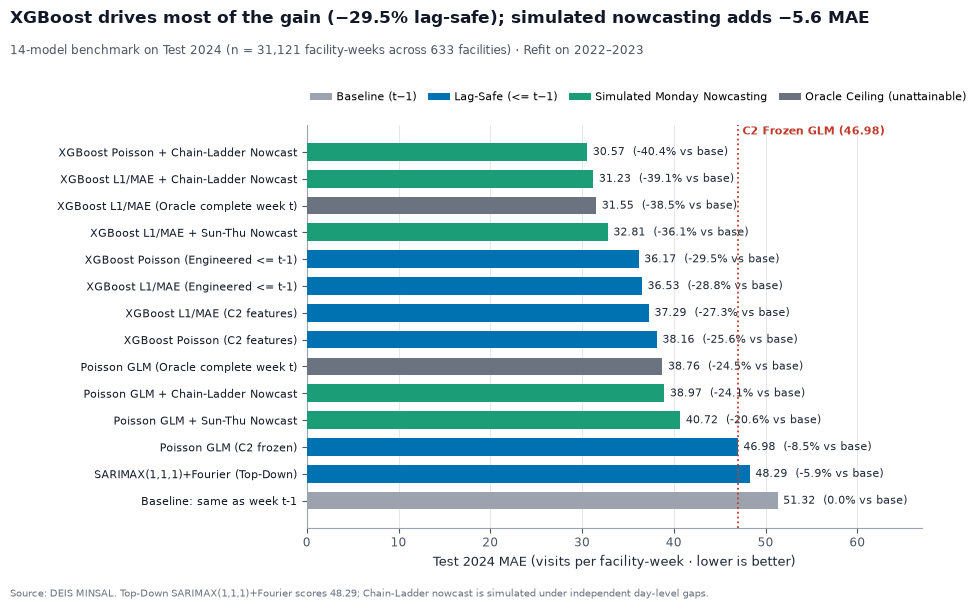

In [4]:
# Benchmark Visual (styled with src/visual_system.py)
plot_df = bench.sort_values('Test24_MAE', ascending=False).reset_index(drop=True)
color_map = {
    '1. Lag-Safe (<= t-1)': PALETTE['model'],
    '2. Monday Nowcasting': PALETTE['nowcast'],
    '3. Oracle Ceiling (Not Mon)': PALETTE['baseline'],
}
bar_colors = [
    '#9CA3AF' if 'Baseline' in m else color_map[g]
    for g, m in zip(plot_df['Group'], plot_df['Model'])
]

fig, ax = plt.subplots(figsize=(10.6, 6.2))
fig.subplots_adjust(left=0.34, right=0.92, top=0.78, bottom=0.13)
style_axes(ax, grid_axis='x')

y = np.arange(len(plot_df))
ax.barh(y, plot_df['Test24_MAE'], color=bar_colors, height=0.66, zorder=3)
ax.axvline(c2_mae, color=PALETTE['alert'], linestyle=':', lw=1.3, zorder=4)
ax.text(c2_mae + 0.5, len(plot_df) - 0.35, f'C2 Frozen GLM ({c2_mae:.2f})',
        fontsize=8.0, fontweight='bold', color=PALETTE['alert'])

for i, row in plot_df.iterrows():
    sign = '+' if row['vs_Baseline_pct'] > 0 else ''
    ax.text(row['Test24_MAE'] + 0.6, i, f"{row['Test24_MAE']:.2f}  ({sign}{row['vs_Baseline_pct']:.1f}% vs base)",
            va='center', ha='left', fontsize=7.9, color=PALETTE['text'])

ax.set_yticks(y)
ax.set_yticklabels(plot_df['Model'], fontsize=8.2, color=PALETTE['observed'])
ax.set_xlim(0, 67)
ax.set_xlabel('Test 2024 MAE (visits per facility-week · lower is better)')

handles = [
    Patch(facecolor='#9CA3AF', label='Baseline (t−1)'),
    Patch(facecolor=PALETTE['model'], label='Lag-Safe (<= t−1)'),
    Patch(facecolor=PALETTE['nowcast'], label='Simulated Monday Nowcasting'),
    Patch(facecolor=PALETTE['baseline'], label='Oracle Ceiling (unattainable)'),
]
add_top_legend(ax, handles, ncol=4, y_offset=1.03, fontsize=7.8)
add_header_footer(
    fig,
    title='XGBoost drives most of the gain (−29.5% lag-safe); simulated nowcasting adds −5.6 MAE',
    subtitle='14-model benchmark on Test 2024 (n = 31,121 facility-weeks across 633 facilities) · Refit on 2022–2023',
    footer='Source: DEIS MINSAL. Top-Down SARIMAX(1,1,1)+Fourier scores 48.29; Chain-Ladder nowcast is simulated under independent day-level gaps.',
)
plt.show()

## 3. Why Each Model Behaved As It Did

1. **XGBoost vs. C2 Poisson GLM (`46.98 → 36.17` lag-safe; `37.29` with identical C2 features):**
   * Poisson GLM uses a single smooth 1st-order cosine wave (`sin/cos`), which cannot bend sharply enough for Chile's asymmetric winter surge (steep climb in May, abrupt drop in June). Gradient boosted trees capture non-linear seasonal shape and facility-size interactions, cutting MAE by **`-20.6%` to `-23.0%`** over C2 GLM even with strictly `<= t-1` inputs.
2. **Simulated Monday Nowcasting (`36.17 → 30.57` for XGBoost; `46.98 → 38.97` for Poisson GLM):**
   * For Poisson GLM, adding the simulated Monday Chain-Ladder nowcast recovers **97.4% of the Oracle week-$t$ ceiling** (`38.97` vs. `38.76`) and trims peak lag from 3 weeks to 2 weeks.
   * For XGBoost Poisson, simulated nowcasting adds a further **`-5.6` MAE reduction** (`36.17 → 30.57`, `WAPE = 17.46%`, `Bias = +1.79%`).
3. **Why Top-Down SARIMAX(1,1,1) + Fourier (`48.29`) Underperformed:**
   * With only ~2 post-pandemic annual cycles (`104` weeks), first-differencing (`d=1`) extrapolated a brief March back-to-school bump into an April overshoot and preserved the 3-week May peak lag (`208.1k` on `2 Jun`). Global panel models (Poisson GLM and XGBoost) leverage cross-sectional strength across all 633 facilities far better.

## 4. Care-Setting Breakdown, Peak Timing & Honest Limitations

Below are the exact `Test 2024` care-setting accuracy breakdown and national peak timing of the updated model (`XGBoost Poisson + Simulated Chain-Ladder Nowcast`).

In [5]:
by_cs = pd.read_csv(W3_V2_DATA / 'w3_v2_test_mae_by_care_setting.csv')
nat24 = pd.read_csv(W3_V2_DATA / 'w3_v2_test_2024_weekly_national.csv', parse_dates=['target_week_start'])

print('--- Table 2A: Test 2024 Facility-Week MAE by Care Setting (XGBoost + Sim. Nowcast) ---')
display(by_cs)

may_rows = nat24.loc[nat24['target_week_start'].between('2024-05-05', '2024-06-09'),
                     ['target_week_start', 'target_resp', 'model_pred', 'baseline_pred']].round(1)
print('--- Table 2B: Winter Surge Window (May–June 2024, thousand visits) — Showing Flat Model Plateau ---')
display(may_rows)

oct_peak = nat24.loc[nat24['target_week_start'].dt.month.eq(10)].sort_values('model_residual', ascending=False).iloc[0]
print(f"Factual October overshoot: {oct_peak['target_week_start'].date()} | Observed={oct_peak['target_resp']:.1f}k | "
      f"Model={oct_peak['model_pred']:.1f}k | Residual=+{oct_peak['model_residual']:.1f}k")

--- Table 2A: Test 2024 Facility-Week MAE by Care Setting (XGBoost + Sim. Nowcast) ---


,type_l1,rows,mean_observed,MAE_baseline,MAE_model,MAE change (%)
0,CEAR,31,5.23,3.00,5.31,76.87
1,Hospital,9256,142.73,41.87,26.15,-37.54
2,SAPU,11007,209.83,60.92,35.41,-41.87
3,SAR,4728,296.78,82.08,47.25,-42.44
4,SUR,6092,67.78,24.56,15.62,-36.40
5,NaN,7,159.86,159.86,106.47,-33.40


--- Table 2B: Winter Surge Window (May–June 2024, thousand visits) — Showing Flat Model Plateau ---


,target_week_start,target_resp,model_pred,baseline_pred
18,2024-05-05,170.0,170.9,123.4
19,2024-05-12,201.7,182.0,142.2
20,2024-05-19,186.6,178.8,159.9
21,2024-05-26,143.8,183.7,169.7
22,2024-06-02,124.4,146.0,201.6
23,2024-06-09,96.3,112.0,185.3


Factual October overshoot: 2024-10-06 | Observed=119.5k | Model=147.9k | Residual=+28.4k


### Key Methodological & Operational Limitations (Non-Causal Scope)
1. **Simulated vs. Real Block-Correlated Nowcasting:** Our `1.58%` week-$t$ nowcast WAPE assumes independent day-level reporting gaps from the `Wed 4 Nov 2026` snapshot. If real facilities delay all 7 days in a block during winter surges, realized Monday MAE will lie between `30.57` (independent nowcast) and `36.17` (strict lag-safe XGBoost).
2. **Flat May Plateau & `6 Oct` Overshoot (`+28.4k`):** XGBoost + Nowcast reaches `182.0k` on `12 May` and `183.7k` on `26 May` (nominal 2-week lag on a flat plateau) and shows a `+28.4k` overshoot on `6 Oct` (`147.9k` vs. `119.5k`). Whether seasonal Fourier features cause this overshoot is a **hypothesis requiring an ablation test**, not a proven mechanism.
3. **Small-Sample Unreliability (`CEAR`, `n = 31`):** `CEAR` facilities average only `5.2` respiratory visits/week (`n = 31` rows); raw MAE rises from `3.00` to `5.31` (`+2.31` visits). Operational use should focus on `SAR`, `SAPU`, `Hospital`, and `SUR` (`n = 31,083` rows, `−36.4%` to `−42.4%` MAE).
4. **Non-Causal & Historical Exploration Caveat:** All forecasts are strictly predictive (not causal), omit predictive uncertainty intervals, and `2024` was previously explored descriptively in C1 (though zero C2/C3 hyperparameters were tuned on `2024`).